# RD: curvatura, ancho de banda e identificación

## Resumen
En DGP sintético de curvatura asimétrica, el baseline global h=1 presenta RMSE=0.67192; local h=0,2 RMSE=0.08295. Una ventana más estrecha h=0,08 empeora RMSE=0.12844 por varianza. Localizar no corrige una discontinuidad de Y(0): no confundir buen ajuste con identificación causal. S2 de este componente, no validación empírica.

## Problema económico y tres ideas candidatas

Se compararon ampliar AR con HAC, invertir AR y abrir auditoría RD. Se eligió RD por diversificación de estimandos económicos y brecha no cubierta, manteniendo MVP pequeño. Pregunta: ¿restringir extrapolación lineal reduce error de un efecto de política en umbral cuando las funciones son curvas? ¿Qué pasa si se rompe continuidad?

## Método y supuestos

Running x uniforme[-1,1], tratamiento $T=1[x\ge0]$, potencial $Y(0)=.4x+3x^2+\kappa Tx^2+\lambda T+\epsilon$, efecto constante $Y(1)-Y(0)=1$, $\epsilon\sim N(0,.3^2)$. Con λ=0, esperanza Y(0) continua aunque κ=4 produzca curvaturas distintas. Con λ=0,6 la continuidad falla. Observar discontinuidad no identifica por sí mismo el efecto del tratamiento.

Kernel uniforme $1[|x|\le h]$, regresiones lineales independientes por lado. $\hat\tau_h=\hat a_+(h)-\hat a_-(h)$, $\hat a_s=\bar y_s-\hat b_s\bar x_s$. Baseline usa h=1 y exactamente mismas pendientes separadas; solo cambia h. No implementamos CCT, RBC ni intervalos causales.

In [1]:
import json,csv
from pathlib import Path
import numpy as np
from IPython.display import display,Image
from src.rd import estimate,sample
root=Path.cwd()
r=json.loads((root/"results/summary.json").read_text())
print(json.dumps(r["config"],ensure_ascii=False,indent=2))

{
  "seed": 20261025,
  "replications": 1500,
  "n": 1200,
  "truth": 1.0,
  "noise_sd": 0.3,
  "bandwidths": [
    1.0,
    0.4,
    0.2,
    0.08
  ],
  "hypothesis": "Curvature4 with valid continuity: h0.2 RMSE <=0.5 times h1 RMSE; do not force confirmation. h0.08 variance ablation; latentjump0.6 falsifies identification.",
  "scenarios": [
    {
      "name": "Smooth symmetric",
      "curvature": 0,
      "latent_jump": 0
    },
    {
      "name": "Asymmetric curvature",
      "curvature": 4,
      "latent_jump": 0
    },
    {
      "name": "Continuity violated",
      "curvature": 4,
      "latent_jump": 0.6
    }
  ]
}


## Sesgo poblacional calculable

Para U[0,h], la proyección lineal de $q x^2$ tiene intercepto $-qh^2/6$. Por simetría ocurre lo mismo en el lado negativo. Luego $\tau_h^{proj}=1+\lambda-\kappa h^2/6$. Es una propiedad algebraica del DGP uniforme cuadrático, no teorema general sobre todos los RD.

Compruébalo con malla densa sin ruido; no confundir esta comprobación numérica con evidencia empírica.

In [2]:
x=np.linspace(-1,1,100000)
t=(x>=0)
y=t+.4*x+3*x*x+4*t*x*x
for h in [1,.4,.2,.08]:
 expected=1-4*h*h/6
 actual=estimate(x,y,h)[0]
 print("h",h,"Proyección",expected,"Malla",actual)
 assert abs(actual-expected)<1e-4

h 1 Proyección 0.33333333333333337 Malla 0.3333199996666594
h 0.4 Proyección 0.8933333333333333 Malla 0.8933311998346637
h 0.2 Proyección 0.9733333333333334 Malla 0.9733327998586638
h 0.08 Proyección 0.9957333333333334 Malla 0.995733247865384


## Datos y estimador
1.500 seeds por escenario, n1200; total18.000 estimaciones(3 escenarios×4ventanas×1500). Datos generados localmente y CSV crudo versionado con recuentos por lado. Mismas realizaciones entre h y mismo seed entre escenarios: comparar pareado. Sin población observada, sin datos sensibles.

In [3]:
x,y=sample(20261025,1200)
for h in [1,.4,.2,.08]:
 value,nl,nr=estimate(x,y,h)
 print("h",h,"salto",round(value,5),"n izquierda/derecha",nl,nr)
print("Este es un ejemplo, no la conclusión Monte Carlo.")

h 1 salto 0.3201 n izquierda/derecha 618 582
h 0.4 salto 0.83209 n izquierda/derecha 255 223
h 0.2 salto 0.84912 n izquierda/derecha 132 119
h 0.08 salto 0.88409 n izquierda/derecha 52 53
Este es un ejemplo, no la conclusión Monte Carlo.


## Resultados de todas las réplicas
Sesgo y RMSE usan el efecto verdadero conocido1. SD es variabilidad entre realizaciones. MC SE de la media no es un IC de efecto en una muestra. Cuantiles q025/q975 son cuantiles Monte Carlo, no intervalos inferenciales.

In [4]:
rows=list(csv.DictReader((root/"results/replications.csv").open()))
assert len(rows)==18000
for s in r["summary"]:
 print(s["scenario"],"h",s["h"],"media",round(s["mean"],5),"sesgo",round(s["bias"],5),"RMSE",round(s["rmse"],5),"SD",round(s["sd"],5),"MCSE",round(s["mean_mc_se"],5))

Smooth symmetric h 1.0 media 0.99863 sesgo -0.00137 RMSE 0.04688 SD 0.04688 MCSE 0.00121
Smooth symmetric h 0.4 media 0.99888 sesgo -0.00112 RMSE 0.05534 SD 0.05535 MCSE 0.00143
Smooth symmetric h 0.2 media 0.99755 sesgo -0.00245 RMSE 0.07751 SD 0.0775 MCSE 0.002
Smooth symmetric h 0.08 media 0.99236 sesgo -0.00764 RMSE 0.12808 SD 0.12789 MCSE 0.0033
Asymmetric curvature h 1.0 media 0.33133 sesgo -0.66867 RMSE 0.67192 SD 0.06603 MCSE 0.0017
Asymmetric curvature h 0.4 media 0.89201 sesgo -0.10799 RMSE 0.12197 SD 0.05673 MCSE 0.00146
Asymmetric curvature h 0.2 media 0.97069 sesgo -0.02931 RMSE 0.08295 SD 0.07763 MCSE 0.002
Asymmetric curvature h 0.08 media 0.98804 sesgo -0.01196 RMSE 0.12844 SD 0.12792 MCSE 0.0033
Continuity violated h 1.0 media 0.93133 sesgo -0.06867 RMSE 0.09525 SD 0.06603 MCSE 0.0017
Continuity violated h 0.4 media 1.49201 sesgo 0.49201 RMSE 0.49527 SD 0.05673 MCSE 0.00146
Continuity violated h 0.2 media 1.57069 sesgo 0.57069 RMSE 0.57595 SD 0.07763 MCSE 0.002
Continu

## Comparación visual
Panel izquierdo: media y±1,96SE Monte Carlo. Panel derecho: RMSE respecto al efecto verdadero. Bandwidth pequeño reduce sesgo de curvatura pero puede aumentar varianza.

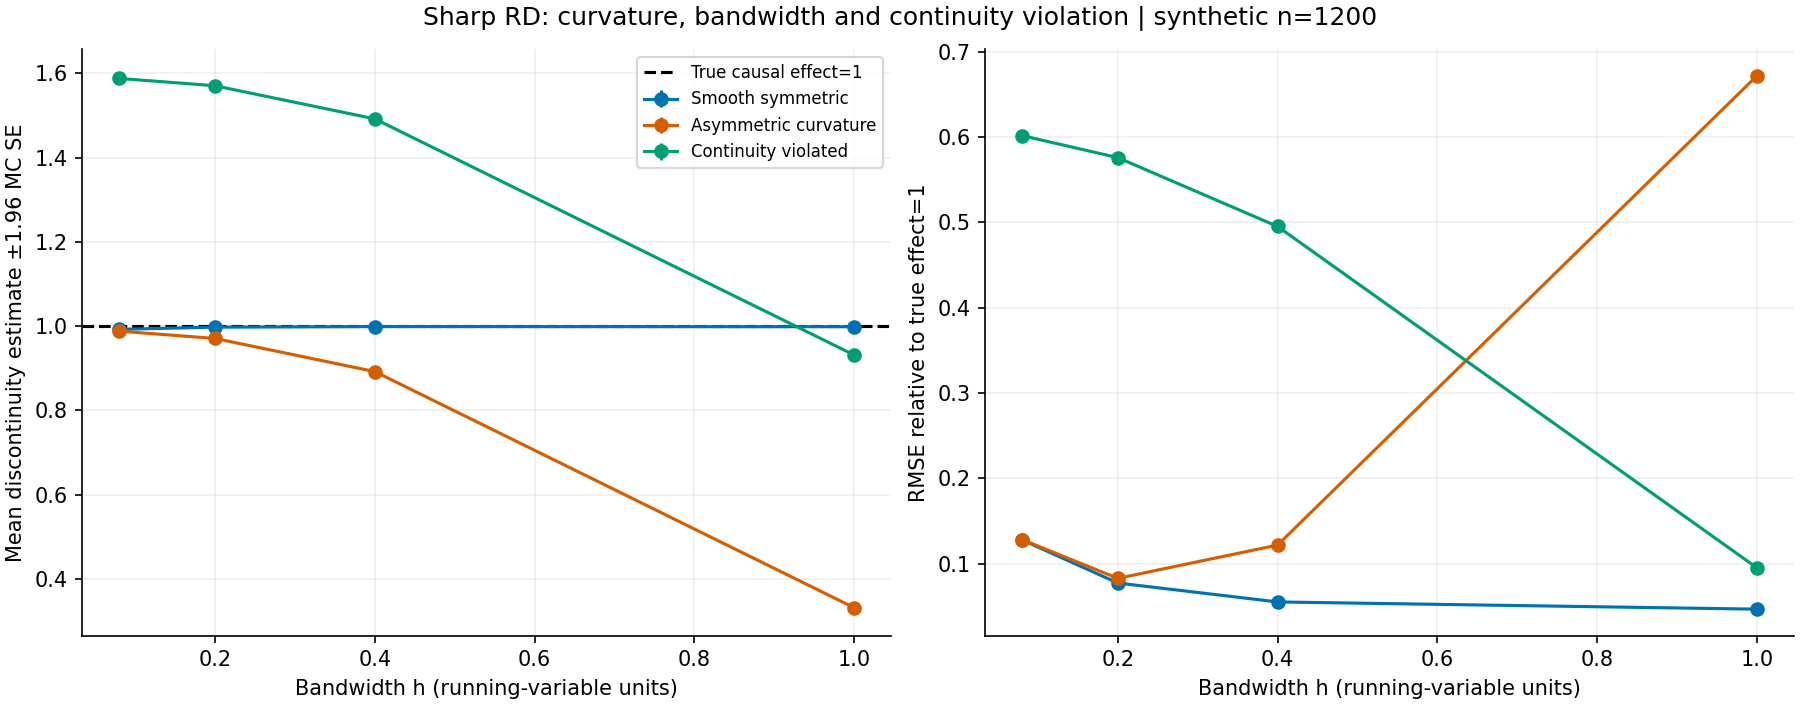

In [5]:
display(Image(filename=str(root/"results/comparison.png")))

## Hipótesis y contrafactual negativo
Criterio previo: RMSE local h0,2≤50% de global en curvatura asimétrica válida. La ventana h0,08 es ablation de varianza. Se reporta también dónde falla la recomendación, sin seleccionar el mejor h usando la verdad para una política real.

In [6]:
valid=[s for s in r["summary"] if s["scenario"]=="Asymmetric curvature"]
ratio=valid[2]["rmse"]/valid[0]["rmse"]
print("Ratio RMSE h.2/global",ratio,"Criterio",ratio<=.5)
print("h.08 peor que h.2",valid[3]["rmse"]>valid[2]["rmse"])
print("Diferencia MSE pareada",valid[2]["paired_mse_difference"],"SE",valid[2]["paired_mse_se"])

Ratio RMSE h.2/global 0.12345583710097358 Criterio True
h.08 peor que h.2 True
Diferencia MSE pareada -0.44460023497323997 SE 0.0022694422673686797


## Falsación de identificación
λ0,6 provoca salto latente en Y(0). Efecto causal verdadero permanece1, pero h→0 identifica salto observado1,6. El baseline puede parecer cercano a1 por cancelación de dos sesgos: esa coincidencia tampoco valida causalidad.

In [7]:
invalid=[s for s in r["summary"] if s["scenario"]=="Continuity violated"]
for s in invalid:print("h",s["h"],"media",s["mean"],"efecto verdadero1","salto límite1.6")
print("Acercarse a1.6 no recupera efecto1.")

h 1.0 media 0.9313261840135298 efecto verdadero1 salto límite1.6
h 0.4 media 1.4920146132150296 efecto verdadero1 salto límite1.6
h 0.2 media 1.5706947391874913 efecto verdadero1 salto límite1.6
h 0.08 media 1.5880444079869813 efecto verdadero1 salto límite1.6
Acercarse a1.6 no recupera efecto1.


## Coste y reproducibilidad
Costes instrumentados de100llamadas por brazo/tamaño; memoria Python no RSS, no extrapolar producción. Los hashes vinculan código y ledger. Versiones directas fijadas, no lock transitivo.

In [8]:
print((root/"results/costs.csv").read_text())
print("Versiones",r["versions"])
print("SHA256 datos",r["data_sha256"])
print("SHA256 núcleo",r["source_sha256"])

n,h,calls,seconds,python_peak_bytes
120,1.0,100,0.017508060000068326,7760
120,0.4,100,0.016831622000040625,3312
120,0.2,100,0.01528982399997858,3312
1200,1.0,100,0.019042105999915293,33096
1200,0.4,100,0.01702325499991275,22752
1200,0.2,100,0.01747145600006661,22752
12000,1.0,100,0.03655180900000232,314152
12000,0.4,100,0.03644692500006386,199016
12000,0.2,100,0.03576498299992181,186720

Versiones {'python': '3.12.14', 'numpy': '2.3.5', 'matplotlib': '3.10.8'}
SHA256 datos ae12919be25451699a0d74f3d180112b96c001612b98831a1584db8a1381c55e
SHA256 núcleo a0ec26723b19d302a203217d521fb7cb3bc203ce9ced4898404e36c99b61e5d5


## Límites, preguntas y siguientes pasos
¿Por qué h pequeño empeora un DGP suave simétrico? ¿Cómo seleccionar h sin conocer efecto1? ¿Qué evidencia externa respalda continuidad? No resolvemos inferencia robusta sesgo/RBC, fuzzy RD, manipulación, running discreto, clusters o datos reales. No afirmar que local siempre domina global ni que simulación demuestra causalidad.

Cinco referencias verificadas en referencias.bib; informe14p analiza≥3ideas y selección. Siguiente: comparador rdrobust, selecciónbandwidth válida y falsaciones de manipulación.

Ejecución secuencial IPython limpio en proceso sin kernel/socket;outputs persistidos,errores abortan. Figura revisada en PNG; no certifica todos los frontends.